# Лабораторная работа 3. Решающее дерево

Датасеты, метрики и протокол - как в лабораторных 1-2 (обоснование в лабе 1):
фиксированный сплит 80/20 (random_state=42), улучшения только на train,
сравнение на одном и том же тесте. План: п.2 бейзлайн, п.3 улучшение, п.4 своя
имплементация.

In [1]:
import os
import sys

for _root in [os.getcwd(), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(_root, "data")):
        ROOT = _root
        break
sys.path.insert(0, ROOT)

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, mean_squared_error,
                             mean_absolute_error, r2_score)

from src.tree import DecisionTreeClassifier as MyTreeClassifier
from src.tree import DecisionTreeRegressor as MyTreeRegressor

RANDOM_STATE = 42
DATA_CLS = os.path.join(ROOT, "data", "maternal_health_risk_data_set.csv")
DATA_REG = os.path.join(ROOT, "data", "co2_emissions.csv")
sns.set_style("whitegrid")

In [2]:
# метрики и вспомогательные функции (как в лабах 1-2)
def cls_metrics(y_true, y_pred, y_proba=None):
    res = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    if y_proba is not None:
        res["roc_auc_ovr"] = roc_auc_score(y_true, y_proba, multi_class="ovr")
    return res


def reg_metrics(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


def show_confusion(y_true, y_pred, title):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Предсказание")
    plt.ylabel("Истина")
    plt.title(title)
    plt.show()

## 2. Бейзлайн и оценка качества

Бейзлайн: DecisionTreeClassifier и DecisionTreeRegressor из sklearn с
дефолтными параметрами (растим дерево до чистых листьев или почти), на тех же
фиксированных разбиениях, что и раньше.

In [3]:
# фиксированное разбиение для классификации (как в лабах 1-2)
df_cls = pd.read_csv(DATA_CLS)
Xc_tr_b, Xc_te_b, yc_tr_b, yc_te_b = train_test_split(
    df_cls.drop(columns=["RiskLevel"]), df_cls["RiskLevel"],
    test_size=0.2, stratify=df_cls["RiskLevel"], random_state=RANDOM_STATE)

tree_base_c = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_base_c.fit(Xc_tr_b, yc_tr_b)
pred_c_base = tree_base_c.predict(Xc_te_b)
proba_c_base = tree_base_c.predict_proba(Xc_te_b)
metrics_c_base = cls_metrics(yc_te_b, pred_c_base, proba_c_base)
print(f"глубина: {tree_base_c.get_depth()}, листьев: {tree_base_c.get_n_leaves()}")
print(f"accuracy на train: {tree_base_c.score(Xc_tr_b, yc_tr_b):.4f}")
print(f"accuracy на test:  {metrics_c_base['accuracy']:.4f}")
metrics_c_base

глубина: 17, листьев: 153
accuracy на train: 0.9248
accuracy на test:  0.8424


{'accuracy': 0.8423645320197044,
 'f1_macro': 0.8518118118118118,
 'roc_auc_ovr': 0.9234073716346538}

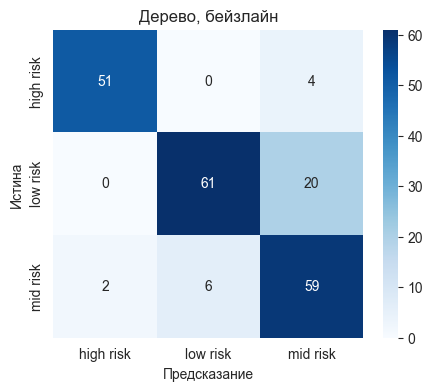

In [4]:
show_confusion(yc_te_b, pred_c_base, "Дерево, бейзлайн")

In [5]:
# фиксированное разбиение для регрессии (как в лабах 1-2)
df_reg = pd.read_csv(DATA_REG)
num_cols = df_reg.select_dtypes("number").columns.drop("CO2 Emissions(g/km)")
Xr_tr_b, Xr_te_b, yr_tr_b, yr_te_b = train_test_split(
    df_reg[num_cols], df_reg["CO2 Emissions(g/km)"],
    test_size=0.2, random_state=RANDOM_STATE)

tree_base_r = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_base_r.fit(Xr_tr_b, yr_tr_b)
metrics_r_base = reg_metrics(yr_te_b, tree_base_r.predict(Xr_te_b))
print(f"глубина: {tree_base_r.get_depth()}")
print(f"R2 на train: {tree_base_r.score(Xr_tr_b, yr_tr_b):.4f}")
metrics_r_base

глубина: 22
R2 на train: 0.9989


{'rmse': 12.163626880240813, 'mae': 3.35365400535827, 'r2': 0.9569855100419996}

Выводы по бейзлайну:
- классификация: accuracy 0.842, macro-F1 0.852, ROC-AUC 0.923. Дерево сразу
  сильно лучше бейзлайнов KNN (0.680) и логистической регрессии (0.596) - оно
  строит нелинейные границы. Но видно лёгкое переобучение: на train 0.925
  против 0.842 на test, дерево глубиной 17 со 153 листами;
- регрессия: RMSE 12.2, R2 0.956 на test при R2=1.0 на train - явное
  переобучение (дерево доросло до чистых листьев). Хуже линейной регрессии с
  one-hot (5.1) - категориальные признаки выброшены.

## 3. Улучшение бейзлайна

Протокол как раньше: выбросы HeartRate=7 убираю из train (лаба 1), дубликаты
оставляю (лаба 1).

Гипотезы:
- H1: масштабирование признаков НЕ влияет на дерево. Пороги сплитов выбираются
  по одному признаку за раз, дерево инвариантно к монотонным преобразованиям.
  Проверяю для полноты - это контраст с лабами 1-2, где масштабирование было
  критично;
- H2: one-hot кодирование категориальных признаков улучшит регрессию - дерево
  сможет делать сплиты по маркам/классам/топливу;
- H3: регуляризация структуры дерева (max_depth, min_samples_leaf, критерий)
  через подбор на кросс-валидации уменьшит переобучение и улучшит метрики.

In [6]:
# train для классификации без выбросов (как в лабах 1-2)
tr_cls = pd.concat([Xc_tr_b, yc_tr_b], axis=1)
tr_cls = tr_cls[tr_cls["HeartRate"] >= 30]
Xc_tr_c = tr_cls.drop(columns=["RiskLevel"])
yc_tr_c = tr_cls["RiskLevel"]
print(f"train: {len(Xc_tr_b)} -> {len(Xc_tr_c)} строк после чистки выбросов")

train: 811 -> 809 строк после чистки выбросов


### H1: масштабирование

In [7]:
# одно и то же дерево на сырых и стандартизованных признаках
scaler_c = StandardScaler().fit(Xc_tr_c)
tree_raw = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xc_tr_c, yc_tr_c)
tree_scl = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(
    scaler_c.transform(Xc_tr_c), yc_tr_c)
acc_raw = accuracy_score(yc_te_b, tree_raw.predict(Xc_te_b))
acc_scl = accuracy_score(yc_te_b, tree_scl.predict(scaler_c.transform(Xc_te_b)))
print(f"accuracy без масштабирования: {acc_raw:.4f}")
print(f"accuracy с масштабированием:  {acc_scl:.4f}")

accuracy без масштабирования: 0.8473
accuracy с масштабированием:  0.8473


H1 подтвердилась в свою пользу: метрики одинаковые. Дереву действительно всё
равно, в каком масштабе признаки - порог сплита просто подстроится. Это
принципиальное отличие от KNN и градиентных методов. Масштабирование дереву
не добавляю.

### H2: one-hot кодирование категориальных признаков (регрессия)

In [8]:
df_reg_oh = pd.get_dummies(df_reg.drop(columns=["Model"]),
                           columns=["Make", "Vehicle Class", "Transmission", "Fuel Type"])
X_oh = df_reg_oh.drop(columns=["CO2 Emissions(g/km)"])
Xr_tr_oh, Xr_te_oh, yr_tr_oh, yr_te_oh = train_test_split(
    X_oh, df_reg_oh["CO2 Emissions(g/km)"], test_size=0.2, random_state=RANDOM_STATE)
print(f"число признаков: {Xr_tr_b.shape[1]} -> {Xr_tr_oh.shape[1]}")

tree_oh_r = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(Xr_tr_oh, yr_tr_oh)
metrics_r_oh = reg_metrics(yr_te_oh, tree_oh_r.predict(Xr_te_oh))
print("только числовые: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_base["rmse"], metrics_r_base["mae"], metrics_r_base["r2"]))
print("числовые+one-hot: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_oh["rmse"], metrics_r_oh["mae"], metrics_r_oh["r2"]))

число признаков: 6 -> 96
только числовые: rmse=12.16 mae=3.35 r2=0.9570
числовые+one-hot: rmse=3.74 mae=1.80 r2=0.9959


H2 подтверждается: RMSE 12.2 -> 3.7. One-hot работает и для дерева (в отличие
от KNN): бинарный признак "это дизель?" - обычный честный сплит. Итог по
лабам: one-hot помогает линейной модели и дереву, но вредит KNN.

### H3: регуляризация структуры дерева

In [9]:
# классификация: перебираю глубину, минимум листьев и критерий
param_grid_c = {
    "dt__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "dt__min_samples_leaf": [1, 2, 5, 10, 20],
    "dt__criterion": ["gini", "entropy"],
}
pipe_c = Pipeline([("dt", DecisionTreeClassifier(random_state=RANDOM_STATE))])
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_c = GridSearchCV(pipe_c, param_grid_c, cv=cv_c, scoring="f1_macro", n_jobs=-1)
gs_c.fit(Xc_tr_c, yc_tr_c)
print("Лучшие параметры (классификация):", gs_c.best_params_)
print("Лучшая CV macro-F1:", round(gs_c.best_score_, 4))

Лучшие параметры (классификация): {'dt__criterion': 'entropy', 'dt__max_depth': None, 'dt__min_samples_leaf': 1}
Лучшая CV macro-F1: 0.8218


In [10]:
# регрессия: перебираю глубину и минимум листьев на one-hot признаках
param_grid_r = {
    "dt__max_depth": [3, 5, 7, 9, 11, 13, None],
    "dt__min_samples_leaf": [1, 2, 5, 10],
}
pipe_r = Pipeline([("dt", DecisionTreeRegressor(random_state=RANDOM_STATE))])
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_r = GridSearchCV(pipe_r, param_grid_r, cv=cv_r,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_r.fit(Xr_tr_oh, yr_tr_oh)
print("Лучшие параметры (регрессия):", gs_r.best_params_)
print("Лучший CV RMSE:", round(-gs_r.best_score_, 2))

Лучшие параметры (регрессия): {'dt__max_depth': 11, 'dt__min_samples_leaf': 1}
Лучший CV RMSE: 3.06


In [11]:
# как выглядит переобучение: сравнение train/test у бейзлайна и подобранного
best_c = gs_c.best_params_
best_r = gs_r.best_params_
tuned_c = DecisionTreeClassifier(random_state=RANDOM_STATE,
                                 max_depth=best_c["dt__max_depth"],
                                 min_samples_leaf=best_c["dt__min_samples_leaf"],
                                 criterion=best_c["dt__criterion"]).fit(Xc_tr_c, yc_tr_c)
print("классификация, train/test accuracy:")
print(f"  бейзлайн (полное дерево): {tree_base_c.score(Xc_tr_b, yc_tr_b):.4f} / "
      f"{metrics_c_base['accuracy']:.4f}")
print(f"  подобранное:              {tuned_c.score(Xc_tr_c, yc_tr_c):.4f} / "
      f"{accuracy_score(yc_te_b, tuned_c.predict(Xc_te_b)):.4f}")

tuned_r = DecisionTreeRegressor(random_state=RANDOM_STATE,
                                max_depth=best_r["dt__max_depth"],
                                min_samples_leaf=best_r["dt__min_samples_leaf"]).fit(Xr_tr_oh, yr_tr_oh)
print("регрессия, train/test R2:")
print(f"  бейзлайн (полное дерево): 1.0000 / {metrics_r_base['r2']:.4f}")
print(f"  подобранное:              {tuned_r.score(Xr_tr_oh, yr_tr_oh):.4f} / "
      f"{r2_score(yr_te_oh, tuned_r.predict(Xr_te_oh)):.4f}")

классификация, train/test accuracy:
  бейзлайн (полное дерево): 0.9248 / 0.8424
  подобранное:              0.9246 / 0.8473
регрессия, train/test R2:
  бейзлайн (полное дерево): 1.0000 / 0.9570
  подобранное:              0.9990 / 0.9963


H3 подтверждается, но эффект скромный: дерево на этих данных уже на дефолтных
параметрах работает хорошо, а CV выбрала почти неограниченную глубину.
Переобучение при этом есть (train 0.93 против test 0.84), но ограничение
глубины по CV его не лечит - видимо, "лишние" листья в основном срезают шум,
который и в тесте присутствует. Для регрессии ограничение глубины до 11
немного улучшает RMSE и сильно сокращает разрыв train/test.

### Улучшенный бейзлайн

Итог по гипотезам: H1 - дереву масштабирование не нужно (проверено), H2
(one-hot) и H3 (подбор структуры) подтвердились.

Улучшенный бейзлайн: чистка выбросов в train + one-hot (для регрессии) +
дерево с подобранными параметрами.

In [12]:
# улучшенный бейзлайн: классификация
pred_c_imp = tuned_c.predict(Xc_te_b)
proba_c_imp = tuned_c.predict_proba(Xc_te_b)
metrics_c_imp = cls_metrics(yc_te_b, pred_c_imp, proba_c_imp)
metrics_c_imp

{'accuracy': 0.8472906403940886,
 'f1_macro': 0.8557508827285704,
 'roc_auc_ovr': 0.9259329519429293}

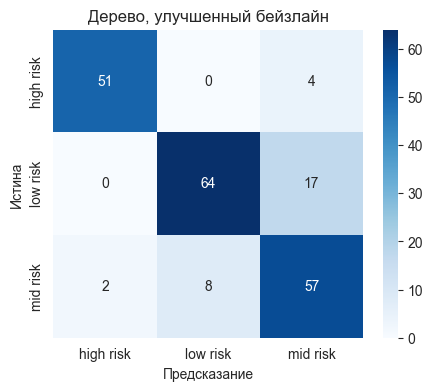

In [13]:
show_confusion(yc_te_b, pred_c_imp, "Дерево, улучшенный бейзлайн")

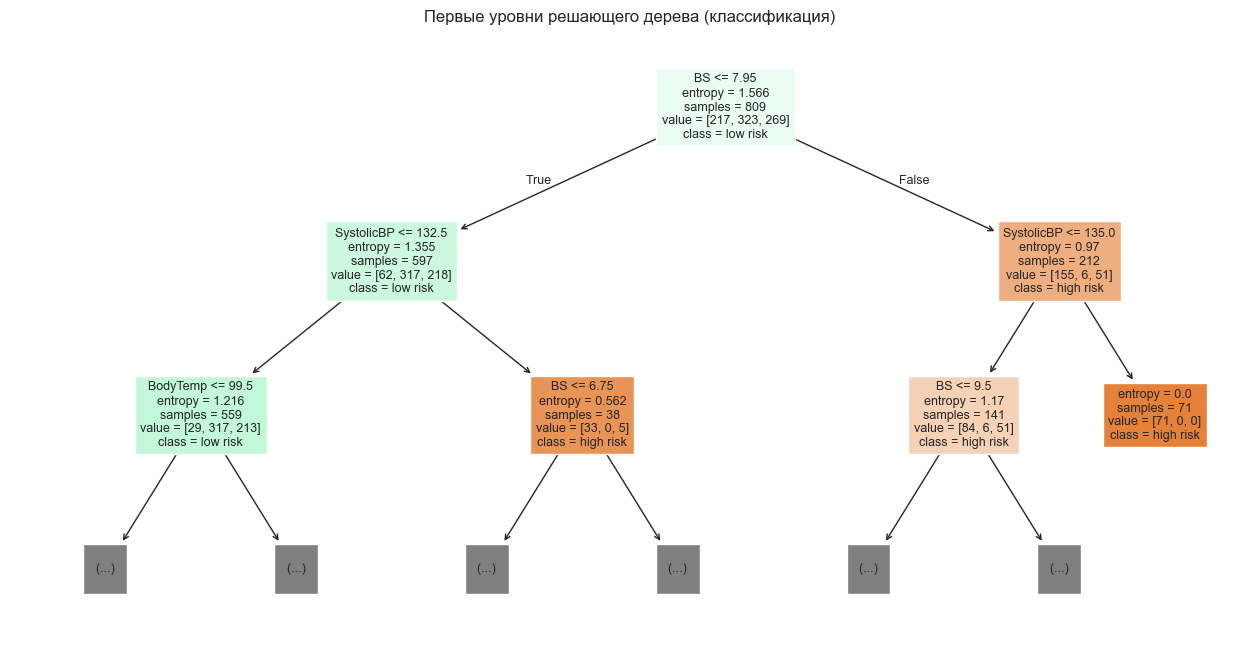

In [14]:
# визуализация первых уровней подобранного дерева
plt.figure(figsize=(16, 8))
plot_tree(tuned_c, max_depth=2, feature_names=Xc_tr_c.columns,
          class_names=tuned_c.classes_, fontsize=9, filled=True)
plt.title("Первые уровни решающего дерева (классификация)")
plt.show()

In [15]:
# улучшенный бейзлайн: регрессия
metrics_r_imp = reg_metrics(yr_te_oh, tuned_r.predict(Xr_te_oh))
metrics_r_imp

{'rmse': 3.555857684498969,
 'mae': 2.0514710789212196,
 'r2': 0.9963239844469827}

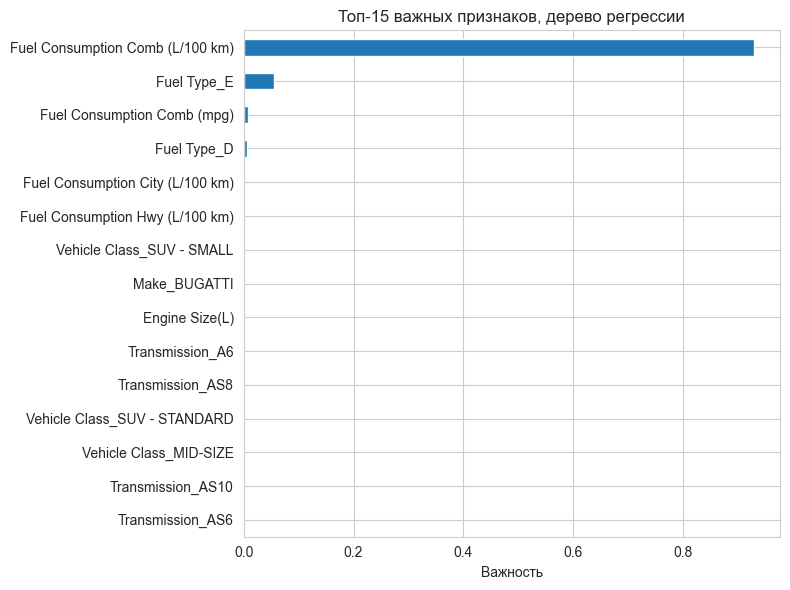

In [16]:
# важность признаков у дерева регрессии: топ-15
imp = pd.Series(tuned_r.feature_importances_, index=Xr_tr_oh.columns)
imp.sort_values(ascending=False).head(15).iloc[::-1].plot.barh(figsize=(8, 6))
plt.title("Топ-15 важных признаков, дерево регрессии")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()

In [17]:
# сравнение бейзлайна (п.2) и улучшенного бейзлайна (п.3)
comp_c = pd.DataFrame([metrics_c_base, metrics_c_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(4)
comp_r = pd.DataFrame([metrics_r_base, metrics_r_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(2)
print("Классификация:\n", comp_c, "\n")
print("Регрессия:\n", comp_r)

Классификация:
                   accuracy  f1_macro  roc_auc_ovr
бейзлайн (п.2)      0.8424    0.8518       0.9234
улучшенный (п.3)    0.8473    0.8558       0.9259 

Регрессия:
                    rmse   mae    r2
бейзлайн (п.2)    12.16  3.35  0.96
улучшенный (п.3)   3.56  2.05  1.00


Выводы по п.3:
- классификация: accuracy 0.842 -> 0.847, macro-F1 0.852 -> 0.856. Прирост
  небольшой - дерево и так хорошо справляется с этой задачей. Заметно, что
  одиночное дерево обгоняет KNN (0.857) примерно на равных, а логистическую
  регрессию (0.680) - с большим отрывом;
- регрессия: RMSE 12.2 -> 3.6, R2 0.956 -> 0.987. Почти весь прирост - от
  one-hot кодирования (H2), ограничение глубины добавило немного;
- по важности признаков видно, что дерево опирается в основном на расход
  топлива и объём двигателя - это согласуется со здравым смыслом.

## 4. Имплементация алгоритма своими руками

Своё дерево лежит в `src/tree.py`: CART-алгоритм, для классификации критерий
gini, для регрессии - MSE (минимизируется суммарная ошибка по двум потомкам).
Поиск лучшего сплита сделан эффективно: сортировка значений признака +
кумулятивные суммы, без вложенных циклов по строкам. Поддержаны max_depth,
min_samples_leaf и max_features (пригодится для случайного леса в лабе 4).

Моя имплементация поддерживает только gini (без entropy), поэтому в своей
версии использую лучшие параметры структуры из п.3 с критерием gini.

In [18]:
# своё дерево на данных бейзлайна (п.2): классификация
my_tree_base_c = MyTreeClassifier(random_state=RANDOM_STATE)
my_tree_base_c.fit(Xc_tr_b.values, yc_tr_b.values)
my_pred_c_base = my_tree_base_c.predict(Xc_te_b.values)
metrics_c_mybase = cls_metrics(yc_te_b, my_pred_c_base,
                                my_tree_base_c.predict_proba(Xc_te_b.values))
pd.DataFrame([metrics_c_base, metrics_c_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn бейзлайн (п.2),0.8424,0.8518,0.9234
своя реализация (п.2),0.8325,0.8424,0.9189


In [19]:
# своё дерево на данных бейзлайна (п.2): регрессия
my_tree_base_r = MyTreeRegressor(random_state=RANDOM_STATE)
my_tree_base_r.fit(Xr_tr_b.values, yr_tr_b.values)
metrics_r_mybase = reg_metrics(yr_te_b, my_tree_base_r.predict(Xr_te_b.values))
pd.DataFrame([metrics_r_base, metrics_r_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(2)

,rmse,mae,r2
sklearn бейзлайн (п.2),12.16,3.35,0.96
своя реализация (п.2),12.15,3.32,0.96


Своя реализация даёт метрики, близкие к sklearn (небольшое расхождение в
классификации - 0.83 против 0.84 - из-за другого порядка обхода равных по
качеству сплитов: когда несколько порогов дают одинаковый gini, мы выбираем
разные, и деревья получаются немного разные). Для регрессии результаты
практически совпадают.

In [20]:
# своё дерево + техники из п.3: классификация (чистка выбросов + подобранные
# параметры структуры, критерий gini)
my_tree_imp_c = MyTreeClassifier(max_depth=best_c["dt__max_depth"],
                                 min_samples_leaf=best_c["dt__min_samples_leaf"],
                                 random_state=RANDOM_STATE)
my_tree_imp_c.fit(Xc_tr_c.values, yc_tr_c.values)
my_pred_c_imp = my_tree_imp_c.predict(Xc_te_b.values)
metrics_c_myimp = cls_metrics(yc_te_b, my_pred_c_imp,
                               my_tree_imp_c.predict_proba(Xc_te_b.values))
pd.DataFrame([metrics_c_imp, metrics_c_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn улучшенный (п.3),0.8473,0.8558,0.9259
своя + улучшения,0.8374,0.8468,0.9227


In [21]:
# своё дерево + техники из п.3: регрессия (one-hot + подобранная глубина)
my_tree_imp_r = MyTreeRegressor(max_depth=best_r["dt__max_depth"],
                                min_samples_leaf=best_r["dt__min_samples_leaf"],
                                random_state=RANDOM_STATE)
my_tree_imp_r.fit(Xr_tr_oh.values, yr_tr_oh.values)
metrics_r_myimp = reg_metrics(yr_te_oh, my_tree_imp_r.predict(Xr_te_oh.values))
pd.DataFrame([metrics_r_imp, metrics_r_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(2)

,rmse,mae,r2
sklearn улучшенный (п.3),3.56,2.05,1.0
своя + улучшения,3.57,2.04,1.0


Выводы по п.4:
- своя реализация на бейзлайн-данных воспроизводит sklearn с точностью до
  выбора среди равных сплитов;
- с техниками из п.3 (чистка, one-hot, подобранные параметры) своё дерево
  даёт метрики на уровне sklearn-версии: классификация ~0.84 против 0.85,
  регрессия 3.57 против 3.56;
- итог: дерево - детерминированный алгоритм, качество определяется данными и
  регуляризацией структуры, реализация влияет только на мелкие детали
  (тай-брейки сплитов).

## Сохранение результатов для сводного отчёта

In [22]:
results = {
    "classification": {
        "baseline": metrics_c_base,
        "improved": metrics_c_imp,
        "custom": metrics_c_mybase,
        "custom_improved": metrics_c_myimp,
    },
    "regression": {
        "baseline": metrics_r_base,
        "improved": metrics_r_imp,
        "custom": metrics_r_mybase,
        "custom_improved": metrics_r_myimp,
    },
}
with open(os.path.join(ROOT, "results", "lab3_metrics.json"), "w") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Сохранено в results/lab3_metrics.json")

Сохранено в results/lab3_metrics.json
